# Salary comparison: NoFluffJobs vs TechCompenso

Median salary for Python-related job postings in each market.

## 1. Imports

In [199]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

## 2. Connect to the database

In [200]:
conn = sqlite3.connect("job_postings.db")

## 3. NoFluffJobs: Python-related postings

In [201]:
nf = pd.read_sql("SELECT * FROM nofluff WHERE (title LIKE '%python%' OR category LIKE '%python%' OR technology LIKE '%python%') AND (`salary.from` > 0 OR `salary.to` > 0)", conn)
nf_py = nf.copy()
nf_py["median_salary"] = (nf_py["salary.from"] + nf_py["salary.to"]) / 2 * 12  # monthly -> yearly
print("NoFluff python postings:", len(nf_py))
print("Median salary:", nf_py["median_salary"].median())

NoFluff python postings: 59
Median salary: 67032.0


## 4. TechCompenso: Python-related postings

In [202]:
tc = pd.read_sql("SELECT * FROM techcompenso WHERE (title LIKE '%python%' OR tags LIKE '%python%') AND (salary_min > 0 OR salary_max > 0)", conn)
tc_py = tc.copy()
tc_py["median_salary"] = (tc_py["salary_min"] + tc_py["salary_max"]) / 2
print("TechCompenso python postings:", len(tc_py))
print("Median salary:", tc_py["median_salary"].median())

TechCompenso python postings: 7
Median salary: 60000.0


## 5. Careerjet: Python-related postings


In [203]:
cj = pd.read_sql("SELECT * FROM careerjet WHERE salary_min > 0 OR salary_max > 0", conn)
cj_py = cj.copy()
cj_py["median_salary"] = (cj_py["salary_min"] + cj_py["salary_max"]) / 2
print("Careerjet python postings:", len(cj_py))
print("Median salary:", cj_py["median_salary"].median())


Careerjet python postings: 111
Median salary: 34000.0


## 6. Compare

In [204]:
comparison = pd.DataFrame({
    "source": ["NoFluffJobs", "TechCompenso", "Careerjet"],
    "python_postings": [len(nf_py), len(tc_py), len(cj_py)],
    "median_salary": [nf_py["median_salary"].median(), tc_py["median_salary"].median(), cj_py["median_salary"].median()],
})
comparison


,source,python_postings,median_salary
0,NoFluffJobs,59,67032.0
1,TechCompenso,7,60000.0
2,Careerjet,111,34000.0


## 7. Close connection

records: 98
saved python_top_companies.csv


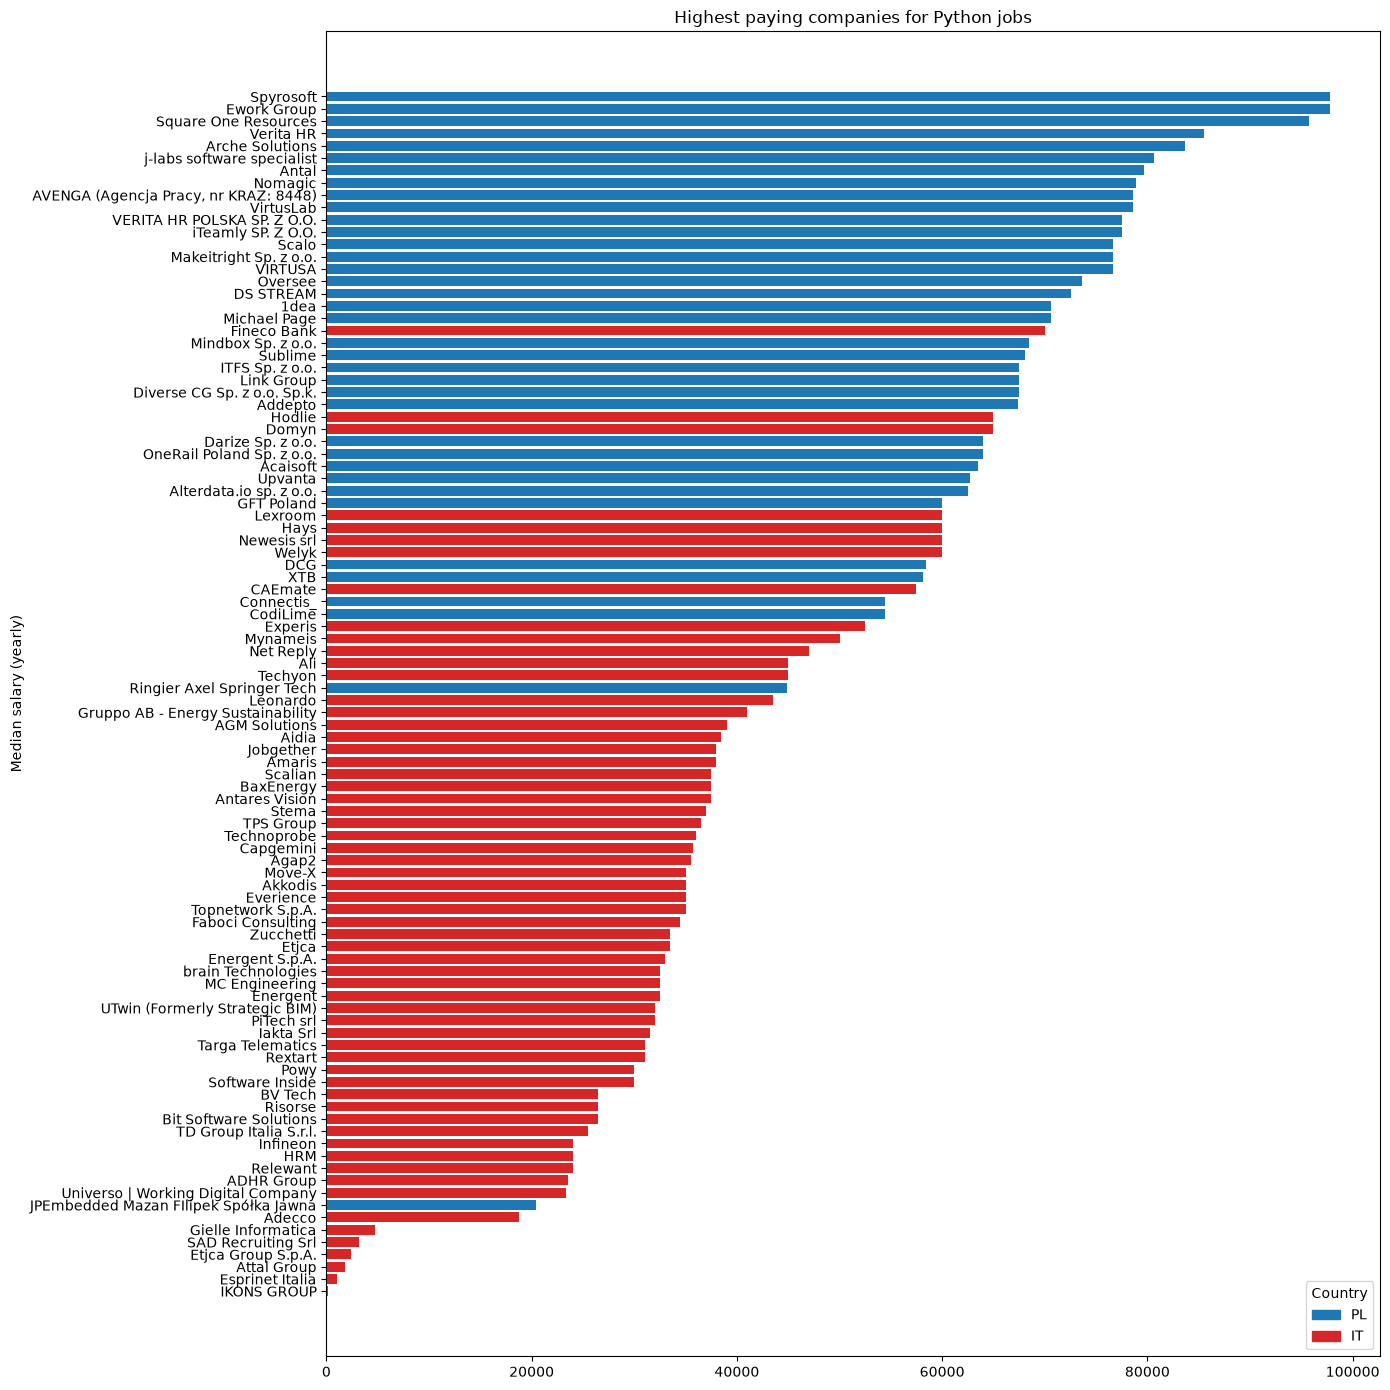

In [205]:
import matplotlib.pyplot as plt

# Top paying companies for Python jobs (combined), with country and best url
nf_top = nf_py[["name", "median_salary", "url"]].copy()
nf_top["company"] = nf_top["name"]
nf_top["country"] = "PL"
tc_top = tc_py[["company", "median_salary", "url"]].copy()
tc_top["country"] = "IT"
cj_top = cj_py[["company", "median_salary", "link"]].copy()
cj_top["country"] = "IT"
cj_top = cj_top.rename(columns={"link": "url"})
all_py = pd.concat([nf_top[["company", "median_salary", "country", "url"]],
                    tc_top[["company", "median_salary", "country", "url"]],
                    cj_top[["company", "median_salary", "country", "url"]]], ignore_index=True)

# for each company keep the highest paying posting's url
all_py["median_salary"] = pd.to_numeric(all_py["median_salary"], errors="coerce")
all_py = all_py.dropna(subset=["company", "median_salary"])
all_py = all_py[all_py["company"].astype(str).str.strip() != ""]
if all_py.empty:
    result = pd.DataFrame(columns=["company", "median_salary", "country", "url"])
else:
    best_idx = all_py.groupby("company")["median_salary"].idxmax()
    result = all_py.loc[best_idx, ["company", "median_salary", "country", "url"]].sort_values("median_salary", ascending=False)
print("records:", len(result))

# save to csv
result.to_csv("python_top_companies.csv", index=False)
print("saved python_top_companies.csv")

colors = {"PL": "#1f77b4", "IT": "#d62728"}
bar_colors = [colors.get(c, "gray") for c in result["country"]]

plt.figure(figsize=(14, 14))
plt.barh(result["company"], result["median_salary"], color=bar_colors)
plt.title("Highest paying companies for Python jobs")
plt.ylabel("Median salary (yearly)")
plt.yticks()
from matplotlib.patches import Patch
handles = [Patch(color=colors[k], label=k) for k in colors]
plt.legend(handles=handles, title="Country")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [206]:
conn.close()

In [207]:
result


,company,median_salary,country,url
57,Spyrosoft,97776.0,PL,openstack-cloud-engineer-spyrosoft-remote
41,Ework Group,97776.0,PL,python-backend-engineer-ework-group-warsaw
32,Square One Resources,95760.0,PL,senior-data-scientist-square-one-resources-rem...
46,Verita HR,85554.0,PL,senior-aws-python-developer-verita-hr-krakow
7,Arche Solutions,83664.0,PL,senior-mlops-engineer-m-f-arche-solutions-remote
...,...,...,...,...
68,SAD Recruiting Srl,3200.0,IT,https://www.careerjet.it/jobad/itfb0f498a0a7b7...
93,Etjca Group S.p.A.,2400.0,IT,https://www.careerjet.it/jobad/itf44fb4bdb6cc1...
171,Attal Group,1800.0,IT,https://www.careerjet.it/jobad/itcc88f96e86c0c...
119,Esprinet Italia,1000.0,IT,https://www.careerjet.it/jobad/it2425523dc160a...
